# TokenGate inference: original implementation and vLLM

[TokenGate](https://arxiv.org/abs/2610.26754) learns which prompt tokens to keep for the later model layers. This notebook uses the released Qwen3 and Qwen3.5 checkpoints to retrieve a fact hidden in a long text.

In this notebook, we'll compare the original TokenGate implementation with vLLM at $K=64$, $K=512$, $K=2{,}048$, $K=4{,}096$, $K=8{,}192$, and **All**. $K$ counts retained tokens from the text; instructions and the question stay protected. **All** keeps every token while still applying TokenGate's learned attention adjustments.

We'll also compare latency with pretrained Qwen running in vLLM without TokenGate.

## 1. Set up

Use Linux with an idle CUDA GPU, CUDA PyTorch, and the installed [TokenGate vLLM fork](https://github.com/luis-gasparschroeder/vllm/tree/lgs/tokengate). From the TokenGate repository root, install the notebook dependencies and build its attention kernel:

```bash
uv pip install --python .venv/bin/python -e '.[benchmark]' ipykernel matplotlib-inline
.venv/bin/python kernels/fa2bias/build.py
```

Set `VLLM_SOURCE` to the vLLM checkout and `GPU` to the device you want to use. If the attention kernel is already built for your PyTorch/CUDA environment, set `FA2BIAS_SITE` to that build instead. Both checkpoints are public; no Hugging Face token is needed.

In [1]:
import json
import os
import subprocess
import sys
from datetime import datetime, timezone
from pathlib import Path
from runpy import run_path

from rich.console import Console
from rich.table import Table

console = Console(width=140)
ROOT = Path.cwd().resolve()
if ROOT.name == "examples":
    ROOT = ROOT.parent
assert (ROOT / "benchmarks/run_vllm_benchmark.py").is_file(), "Open this notebook in the TokenGate checkout."
os.chdir(ROOT)

helpers = run_path(str(ROOT / "examples/inference-vllm-helper.py"))
load_results = helpers["load_results"]
plot_comparison = helpers["plot_comparison"]

# Optional: a JSON list of completed run directories; unset to run inference.
SAVED_RUNS = [
    Path(path) for path in json.loads(os.environ.get("TOKEN_GATE_SAVED_RUNS", "[]"))
]
VLLM_SOURCE = Path(os.environ.get("VLLM_SOURCE", str(ROOT.parent / "vllm"))).resolve()
ORIGINAL_PYTHON = sys.executable
VLLM_PYTHON = sys.executable
GPU = "0"
N_EXAMPLES = 1
WARMUPS = 2
REPEATS = 5
ENGINES = ["original", "vllm", "vllm_tiled", "vllm_base", "vllm_base_triton"]
PROFILE = False  # Capture an extra, untimed full-context trace per implementation.
CONFIGS = [
    ROOT / "benchmarks/configs/vllm_niah_qwen3.yaml",
    ROOT / "benchmarks/configs/vllm_niah_qwen3_5.yaml",
]
OUTPUT = (
    SAVED_RUNS[0].parent if SAVED_RUNS
    else ROOT / "results/vllm-benchmark" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S.%fZ")
)
if SAVED_RUNS:
    manifests = [json.loads((run / "manifest.json").read_text()) for run in SAVED_RUNS]
    console.print("Loading saved measurements; inference will not run again.")
else:
    assert (VLLM_SOURCE / "tools/export_token_gate.py").is_file(), "Set VLLM_SOURCE to your vLLM fork."
    console.print(f"New inference run: {N_EXAMPLES} example(s), {WARMUPS} warmup(s), {REPEATS} repetitions.")
console.print(f"Results: {OUTPUT}")

Loading saved measurements; inference will not run again.

Results: /Users/luisgasparschroeder/Desktop/TokenGate/results/vllm-benchmark/20261108-kernel-refine-01/final

### Check the hardware

The next cell reports the CPU, memory, GPU, and software configuration used for inference.

In [2]:
from benchmarks.run_vllm_benchmark import hardware_info

hosts = (
    [(m["config"]["name"], m["hardware"], m["selected_gpu"]) for m in manifests]
    if SAVED_RUNS else [("Current inference host", hardware_info(), GPU)]
)
for label, hardware, selected_gpu in hosts:
    table = Table(title=f"Inference hardware: {label}", show_header=False)
    for name in ("cpu", "logical_cpus", "ram_bytes", "python", "pytorch_cuda_version"):
        value = hardware.get(name, "unavailable")
        if name == "ram_bytes" and isinstance(value, int):
            value = f"{value / 2**30:.1f} GiB"
        table.add_row(name.replace("_", " ").capitalize(), str(value))
    for gpu in hardware["gpus"]:
        if gpu["index"] == selected_gpu:
            table.add_row(f"GPU {selected_gpu}", f"{gpu['name']}, {float(gpu['vram_mib']) / 1024:.1f} GiB")
            table.add_row("GPU driver", gpu["driver"])
    console.print(table)

              Inference hardware: Qwen3-1.7B              
┌──────────────────────┬─────────────────────────────────┐
│ Cpu                  │ AMD EPYC 7742 64-Core Processor │
│ Logical cpus         │ 256                             │
│ Ram bytes            │ 1007.7 GiB                      │
│ Python               │ 3.12.9                          │
│ Pytorch cuda version │ 13.0                            │
│ GPU 0                │ NVIDIA A100-SXM4-80GB, 80.0 GiB │
│ GPU driver           │ 580.82.07                       │
└──────────────────────┴─────────────────────────────────┘

              Inference hardware: Qwen3.5-2B              
┌──────────────────────┬─────────────────────────────────┐
│ Cpu                  │ AMD EPYC 7742 64-Core Processor │
│ Logical cpus         │ 256                             │
│ Ram bytes            │ 1007.7 GiB                      │
│ Python               │ 3.12.9                          │
│ Pytorch cuda version │ 13.0                            │
│ GPU 1                │ NVIDIA A100-SXM4-80GB, 80.0 GiB │
│ GPU driver           │ 580.82.07                       │
└──────────────────────┴─────────────────────────────────┘

## 2. Inspect the checkpoints and example

Each released checkpoint contains a **gate**, which scores prompt tokens, and a **LoRA adapter**, which stores learned updates to Qwen's weights. TokenGate inference uses both. Qwen3 places the gate after layer 1; Qwen3.5 uses layer 3, counting from zero.

We'll use a 32K needle-in-a-haystack example. The question appears before the text so the gate can use it when choosing tokens. Increase `N_EXAMPLES` to include more of the five examples provided with the repository.

In [3]:
import yaml

checkpoints = Table(title="Published checkpoints")
for column in ("Model", "Gate layer", "Checkpoint", "Budgets"):
    checkpoints.add_column(column)
for path in CONFIGS:
    cfg = yaml.safe_load(path.read_text())
    checkpoints.add_row(cfg["name"], str(cfg["gate_layer"]), cfg["checkpoint"], ", ".join([*(f"{k:,}" for k in cfg["k_values"]), "All"]))
console.print(checkpoints)

samples = [json.loads(line) for line in (ROOT / "examples/data/niah_32k_samples.jsonl").read_text().splitlines()]
assert 1 <= N_EXAMPLES <= len(samples)
sample = samples[0]
console.print(f"[bold]Question:[/bold] {sample['question']}")
console.print(f"[bold]Expected answer:[/bold] {sample['answer']}")
console.print(f"[bold]Text preview:[/bold] {sample['body'][:500]}...")

                                       Published checkpoints                                        
┏━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Model      ┃ Gate layer ┃ Checkpoint                         ┃ Budgets                           ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ Qwen3-1.7B │ 1          │ liana313/tokengate-niah-qwen3-1.7b │ 64, 512, 2,048, 4,096, 8,192, All │
│ Qwen3.5-2B │ 3          │ liana313/tokengate-niah-qwen3.5-2b │ 64, 512, 2,048, 4,096, 8,192, All │
└────────────┴────────────┴────────────────────────────────────┴───────────────────────────────────┘

Question: What is the best thing to do in San Francisco?

Expected answer: eat a sandwich and sit in Dolores Park on a sunny day

Text preview: People who worry about the increasing gap between rich and poor generally look back on the mid twentieth century as a golden 
age. In those days we had a large number of high-paying union manufacturing jobs that boosted the median income. I wouldn't quite call the 
high-paying union job a myth, but I think people who dwell on it are reading too much into it. Oddly enough, it was working with startups 
that made me realize where the high-paying union job came from. In a rapidly growing market, you d...

## 3. Run inference

The benchmark tokenizes each sample once per model. All implementations receive those exact token IDs and the same prunable span, $[s,e)$. Only tokens in that span compete for the $K$ places.

[The runner](../benchmarks/run_vllm_benchmark.py) contains the full calls and matched EOS settings; [the vLLM implementation](../benchmarks/vllm_backend.py) sets up the supported engine configuration. Each model is loaded once per implementation. Warmups are excluded from the results. The original worker also checks that enabling streaming leaves the output tokens and retained positions unchanged.

In [4]:
if SAVED_RUNS:
    runs = list(SAVED_RUNS)
    saved_summary, _ = load_results(runs)
    saved_summary = saved_summary[saved_summary.engine.isin(ENGINES)]
    for run, manifest in zip(runs, manifests, strict=True):
        model = manifest["config"]["name"]
        settings = len(saved_summary[saved_summary.model == model])
        console.print(
            f"{model}: loaded {settings} settings, {manifest['warmups']} warmup(s), "
            f"{manifest['repeats']} timing repetitions per setting."
        )
    console.print("Rebuilding tables and plots from the saved measurements.")
else:
    runs = []
    for config in CONFIGS:
        run = OUTPUT / config.stem
        console.rule(f"Run {yaml.safe_load(config.read_text())['name']}")
        command = [
            ORIGINAL_PYTHON, "-m", "benchmarks.run_vllm_benchmark",
            "--config", str(config), "--output", str(run),
            "--n", str(N_EXAMPLES),
            "--warmups", str(WARMUPS), "--repeats", str(REPEATS), "--gpu", GPU,
            "--original-python", ORIGINAL_PYTHON, "--vllm-python", VLLM_PYTHON,
            "--vllm-source", str(VLLM_SOURCE), "--engines", *ENGINES,
        ]
        if PROFILE:
            command.append("--profile")
        run.parent.mkdir(parents=True, exist_ok=True)
        if run.exists():
            raise FileExistsError(f"Choose a new output directory: {run}")
        log = run.parent / f"{config.stem}.log"
        with console.status("Download, warm up, and measure"), log.open("w") as stream:
            completed = subprocess.run(command, cwd=ROOT, stdout=stream, stderr=subprocess.STDOUT)
        if completed.returncode:
            console.print(log.read_text()[-6000:])
            raise RuntimeError(f"Run failed. Details: {log}")
        runs.append(run)
        console.print(f"Finished. Raw results: {run}")


Qwen3-1.7B: loaded 20 settings, 2 warmup(s), 5 timing repetitions per setting.

Qwen3.5-2B: loaded 20 settings, 2 warmup(s), 5 timing repetitions per setting.

Rebuilding tables and plots from the saved measurements.

## 4. Compare the answers

We compare five implementations:

| Implementation | Model setup | Full attention |
| --- | --- | --- |
| **Original TokenGate** | Qwen with the trained gate and LoRA adapter, using the original TokenGate code | TokenGate's FlashAttention-2 kernels |
| **TokenGate in vLLM (Triton)** | The same trained gate and LoRA updates, using vLLM | Triton with TokenGate's learned attention adjustments |
| **TokenGate in vLLM (tiled prefill)** | The same trained gate and LoRA updates, using vLLM | Custom Triton prefill with the learned bias; Triton paged attention during generation |
| **Base Qwen in vLLM (auto)** | Pretrained Qwen, without the gate or LoRA updates | Backend selected by vLLM |
| **Base Qwen in vLLM (Triton)** | Pretrained Qwen, without the gate or LoRA updates | Triton |

The three TokenGate implementations run at $K=64$, $K=512$, $K=2{,}048$, $K=4{,}096$, $K=8{,}192$, and **All**. The two Base Qwen baselines keep every prompt token and do not apply TokenGate's learned attention adjustments.

Compare each answer with the expected phrase. A correct score means the answer contains that phrase after normalization. Different wrong answers receive the same score, so check the text as well as the score.

In [5]:
from benchmarks.run_vllm_benchmark import LABELS

answers = Table(title="Answers to the same question")
for column in ("Model", "Implementation", "K", "Answer", "Correct", "Cap reached"):
    answers.add_column(column)
for run in runs:
    rows = [json.loads(line) for line in (run / "measurements.jsonl").read_text().splitlines()]
    for row in rows:
        if row["engine"] in ENGINES and row["repeat"] == 0 and row["id"] == sample["id"]:
            answers.add_row(row["model"], LABELS[row["engine"]], str(row["budget"]), row["answer"],
                            "yes" if row["correct"] else "no", "yes" if row["hit_output_cap"] else "no")
console.print(answers)

for run in runs:
    validation = json.loads((run / "validation.json").read_text())
    model = json.loads((run / "inputs.json").read_text())["config"]["name"]
    agreement = (
        "Generated tokens match at every tested budget."
        if validation["cross_engine_token_agreement"]
        else "Generated tokens differ for at least one tested budget."
    )
    console.print(f"{model}, original versus Triton: {agreement}")
    if validation.get("kernel_token_agreement") is not None:
        kernel_agreement = "match" if validation["kernel_token_agreement"] else "differ"
        console.print(f"{model}, Triton versus tiled prefill: generated tokens {kernel_agreement}.")

                                                        Answers to the same question                                                        
┏━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ Model      ┃ Implementation                    ┃ K    ┃ Answer                                                   ┃ Correct ┃ Cap reached ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━┩
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 64   │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 512  │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 2048 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 4096 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 8192 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ All  │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Original TokenGate                │ 64   │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Original TokenGate                │ 512  │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Original TokenGate                │ 2048 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Original TokenGate                │ 4096 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Original TokenGate                │ 8192 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Original TokenGate                │ All  │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 64   │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 512  │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 2048 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 4096 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 8192 │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ All  │ eat a sandwich and sit in Dolores Park on a sunny day    │ yes     │ no          │
│ Qwen3-1.7B │ Base Qwen in vLLM (auto)          │ All  │ The best thing to do in San Francisco is to eat a        │ yes     │ no          │
│            │                                   │      │ sandwich and sit in Dolores Park on a sunny day.         │         │             │
│ Qwen3-1.7B │ Base Qwen in vLLM (Triton)        │ All  │ The best thing to do in San Francisco is to eat a        │ yes     │ no          │
│            │                                   │      │ sandwich and sit in Dolores Park on a sunny day.         │         │             │
│ Qwen3.5-2B │ TokenGate in vLLM (tiled prefill) │ 64   │ eat a sandwich and sit on the puppet theater parkway on  │ no      │ no          │
│            │                                   │      │ a sunny day                                              │         │             │
│ Qwen3.5-2B │ TokenGate in vLLM (tiled prefill) │ 5

Qwen3-1.7B, original versus Triton: Generated tokens match at every tested budget.

Qwen3-1.7B, Triton versus tiled prefill: generated tokens match.

Qwen3.5-2B, original versus Triton: Generated tokens differ for at least one tested budget.

Qwen3.5-2B, Triton versus tiled prefill: generated tokens match.

## 5. Compare retrieval and latency

**Time to first token (TTFT)** measures the time from submitting the prepared input tokens to receiving the first generated token. **Time to final token** ends when the last token arrives. Downloads, model loading, and warmup runs are excluded; bars show median latency over the measured repetitions.

The two Base Qwen baselines appear at **K=All** because they process the full prompt. **Auto** lets vLLM select the attention backend; **Triton** forces its Triton attention kernel.

For each model and latency panel, the dashed line marks the faster Base Qwen baseline. Labels above the pruned TokenGate bars show the speedup: baseline latency divided by TokenGate latency. For example, **2.0×** means half the baseline latency.

Each bar also shows retrieval correctness: **✓** for a correct answer and **✗** for an incorrect answer. With more examples, the label shows **correct / total** instead. One example cannot estimate test-set accuracy. Timing repetitions do not increase the sample size.

                                                      Measured results                                                       
┏━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃ Model      ┃ Implementation                    ┃ K    ┃ Correct ┃ TTFT (ms) ┃ Final token (ms) ┃ Output tokens ┃ Tokens/s ┃
┡━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━┩
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 64   │ 1/1     │ 92.7      │ 491.0            │ 14            │ 28.5     │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 512  │ 1/1     │ 100.1     │ 497.9            │ 14            │ 28.0     │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 2048 │ 1/1     │ 125.8     │ 525.5            │ 14            │ 26.6     │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 4096 │ 1/1     │ 164.0     │ 564.2            │ 14            │ 24.6     │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ 8192 │ 1/1     │ 258.1     │ 661.0            │ 14            │ 21.1     │
│ Qwen3-1.7B │ TokenGate in vLLM (tiled prefill) │ All  │ 1/1     │ 1231.7    │ 1639.4           │ 14            │ 8.5      │
│ Qwen3-1.7B │ Original TokenGate                │ 64   │ 1/1     │ 130.1     │ 633.2            │ 14            │ 22.1     │
│ Qwen3-1.7B │ Original TokenGate                │ 512  │ 1/1     │ 130.0     │ 628.7            │ 14            │ 22.1     │
│ Qwen3-1.7B │ Original TokenGate                │ 2048 │ 1/1     │ 147.1     │ 641.4            │ 14            │ 21.7     │
│ Qwen3-1.7B │ Original TokenGate                │ 4096 │ 1/1     │ 199.9     │ 694.9            │ 14            │ 20.0     │
│ Qwen3-1.7B │ Original TokenGate                │ 8192 │ 1/1     │ 307.5     │ 805.6            │ 14            │ 17.3     │
│ Qwen3-1.7B │ Original TokenGate                │ All  │ 1/1     │ 1323.4    │ 2341.6           │ 14            │ 6.0      │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 64   │ 1/1     │ 92.5      │ 492.6            │ 14            │ 28.2     │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 512  │ 1/1     │ 101.6     │ 501.3            │ 14            │ 27.9     │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 2048 │ 1/1     │ 137.0     │ 536.7            │ 14            │ 26.1     │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 4096 │ 1/1     │ 204.4     │ 605.8            │ 14            │ 23.0     │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ 8192 │ 1/1     │ 413.7     │ 834.6            │ 14            │ 16.9     │
│ Qwen3-1.7B │ TokenGate in vLLM (Triton)        │ All  │ 1/1     │ 3646.1    │ 4060.6           │ 14            │ 3.4      │
│ Qwen3-1.7B │ Base Qwen in vLLM (auto)          │ All  │ 1/1     │ 1074.1    │ 1479.0           │ 25            │ 16.8     │
│ Qwen3-1.7B │ Base Qwen in vLLM (Triton)        │ All  │ 1/1     │ 2382.5    │ 2838.3           │ 25            │ 8.8      │
│ Qwen3.5-2B │ TokenGate in vLLM (tiled prefill) │ 64   │ 0/1     │ 119.8     │ 414.7            │ 16            │ 38.7     │
│ Qwen3.5-2B │ TokenGate in vLLM (tiled prefill) │ 512  │ 0/1     │ 125.9     │ 385.9            │ 14            │ 36.3     │
│ Qwen3.5-2B │ TokenGate in vLLM (tiled prefill) │ 2048 │ 1/1     │ 148.2     │ 410.7            │ 14            │ 34.4     │
│ Qwen3.5-2B │ TokenGate in vLLM (tiled prefill) │ 4096 │ 1/1     │ 175.2     │ 435.7            │ 14            │ 32.4     │
│ Qwen3.5-2B │ TokenGate in vLLM (tiled prefill) │ 8192 │ 1/1     │ 233.5     │ 496.8            │ 14            │ 28.1     │
│ Qwen3.5-2B │ TokenGate in vLLM (tiled prefill) │ All  │ 1/1     │ 694.6     │ 960.9            │ 14            │ 14.5     │
│ Qwen3.5-2B │ Original TokenGate                │ 64   │ 0/1     │ 189.4     │ 659.5            │ 16            │ 24.1     │
│ Qwen3.5-2B │ Original TokenGate                │ 512  │ 0/1     │ 189.7     │ 598.3         

Tokens/s uses sequential request wall times, including EOS; it is not saturated serving throughput.

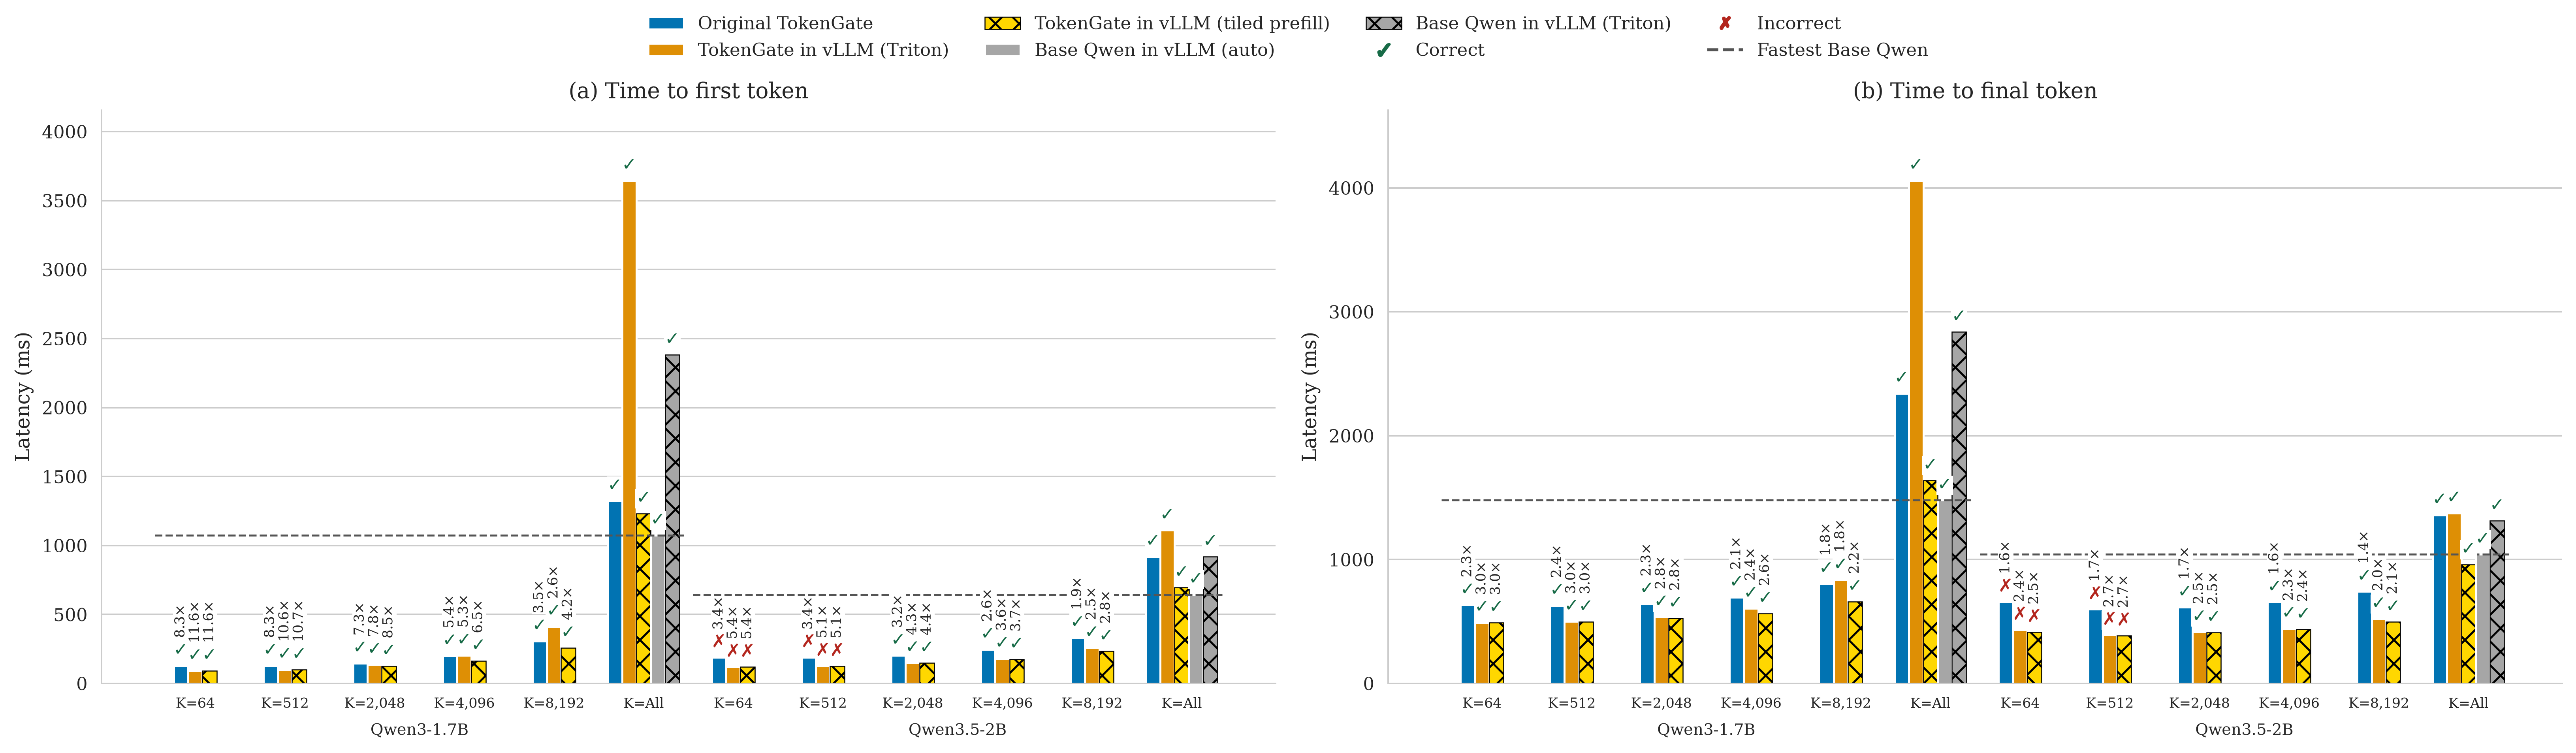

In [6]:
summary, _ = load_results(runs)
summary = summary[summary.engine.isin(ENGINES)]
metrics = Table(title="Measured results")
for column in ("Model", "Implementation", "K", "Correct", "TTFT (ms)", "Final token (ms)", "Output tokens", "Tokens/s"):
    metrics.add_column(column)
for row in summary.to_dict("records"):
    metrics.add_row(row["model"], LABELS[row["engine"]], row["budget"],
                    f"{row['correct']}/{row['examples']}", f"{row['ttft_ms']:.1f}",
                    f"{row['final_ms']:.1f}", f"{row['output_tokens']:g}",
                    f"{row['output_tokens_per_s']:.1f}")
console.print(metrics)
console.print("Tokens/s uses sequential request wall times, including EOS; it is not saturated serving throughput.")

import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("retina", "svg")
figure = plot_comparison(summary, OUTPUT / "comparison")
display(figure)
plt.close(figure)